In [ ]:
# ================================================================
# NOTEBOOK 2 — RFM + CUSTOMER INTELLIGENCE
# Project: E-Commerce Intelligence Platform — Olist Brazil
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------
# CELL 1 — DATA LOADING
# ----------------------------------------------------------------
path = path = "../data_raw/raw/"

orders   = pd.read_csv(path + "olist_orders_dataset.csv")
customers = pd.read_csv(path + "olist_customers_dataset.csv")
payments = pd.read_csv(path + "olist_order_payments_dataset.csv")
order_items = pd.read_csv(path + "olist_order_items_dataset.csv")
reviews  = pd.read_csv(path + "olist_order_reviews_dataset.csv")
products = pd.read_csv(path + "olist_products_dataset.csv")
category = pd.read_csv(path + "product_category_name_translation.csv")

# Date conversion
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

# Clean delivered orders only
orders_clean = orders[orders['order_status'] == 'delivered'].copy()
orders_clean = orders_clean.dropna(subset=['order_delivered_customer_date'])

# Merge payments
df = orders_clean.merge(payments, on='order_id', how='left')

print(f"Data loaded: {len(df):,} records")
print(f"Date range : {orders_clean['order_purchase_timestamp'].min().date()} "
      f"to {orders_clean['order_purchase_timestamp'].max().date()}")


# ----------------------------------------------------------------
# CELL 2 — RFM CALCULATION
# ----------------------------------------------------------------
reference_date = orders_clean['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_id').agg(
    last_order_date = ('order_purchase_timestamp', 'max'),
    frequency       = ('order_id',                'nunique'),
    monetary        = ('payment_value',           'sum')
).reset_index()

rfm['recency']  = (reference_date - rfm['last_order_date']).dt.days
rfm['monetary'] = rfm['monetary'].round(2)
rfm = rfm[['customer_id','recency','frequency','monetary']]

print("RFM TABLE SAMPLE:")
print("=" * 60)
print(rfm.head(10).to_string(index=False))
print(f"\nTotal customers: {len(rfm):,}")

# RFM Distribution Stats
print(f"\nRFM DISTRIBUTION:")
print(f"{'Metric':<12} {'Min':>8} {'Median':>10} {'Mean':>10} {'Max':>8}")
print("-" * 55)
for col in ['recency','frequency','monetary']:
    print(f"{col:<12} {rfm[col].min():>8.0f} {rfm[col].median():>10.1f} "
          f"{rfm[col].mean():>10.1f} {rfm[col].max():>8.0f}")


# ----------------------------------------------------------------
# CELL 3 — FREQUENCY CRISIS ANALYSIS
# WHAT: 96% customers ordered only once — massive retention problem
# WHY:  No repeat purchase = no sustainable business
# HOW:  Loyalty program, personalized re-engagement campaigns
# ----------------------------------------------------------------
freq_dist = rfm['frequency'].value_counts().sort_index()
single_order_pct = (rfm['frequency'] == 1).mean() * 100
repeat_customers = rfm[rfm['frequency'] > 1]
single_customers = rfm[rfm['frequency'] == 1]

repeat_avg_monetary  = repeat_customers['monetary'].mean()
single_avg_monetary  = single_customers['monetary'].mean()
ltv_multiplier       = repeat_avg_monetary / single_avg_monetary

print("FREQUENCY CRISIS ANALYSIS:")
print("=" * 55)
print(f"Single order customers  : {len(single_customers):,}  ({single_order_pct:.1f}%)")
print(f"Repeat customers        : {len(repeat_customers):,}  ({100-single_order_pct:.1f}%)")
print(f"\nSingle order avg spend  : R$ {single_avg_monetary:,.2f}")
print(f"Repeat customer avg spend: R$ {repeat_avg_monetary:,.2f}")
print(f"Repeat customer LTV mult : {ltv_multiplier:.2f}x higher")

# Revenue impact if repeat rate improves
current_repeat_pct = (rfm['frequency'] > 1).mean() * 100
target_repeat_pct  = current_repeat_pct + 10
new_repeat_customers = int(len(rfm) * 0.10)
revenue_opportunity  = new_repeat_customers * repeat_avg_monetary

print(f"\nREVENUE OPPORTUNITY:")
print(f"Current repeat rate     : {current_repeat_pct:.1f}%")
print(f"Target repeat rate      : {target_repeat_pct:.1f}% (+10%)")
print(f"New repeat customers    : {new_repeat_customers:,}")
print(f"Revenue opportunity     : R$ {revenue_opportunity:,.2f}")

# Frequency distribution chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
freq_counts = freq_dist.head(8)
colors_freq = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(freq_counts))]
bars = ax1.bar([str(x) for x in freq_counts.index], freq_counts.values, color=colors_freq)
ax1.set_title('Order Frequency Distribution\n(Red = Single Order Customers)',
              fontsize=11, fontweight='bold')
ax1.set_xlabel('Number of Orders')
ax1.set_ylabel('Number of Customers')
for bar, val in zip(bars, freq_counts.values):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+100,
             f'{val:,}', ha='center', fontsize=9, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.4)

categories_comp = ['Single Order\nCustomers', 'Repeat\nCustomers']
values_comp     = [single_avg_monetary, repeat_avg_monetary]
colors_comp     = ['#e74c3c', '#2ecc71']
bars2 = ax2.bar(categories_comp, values_comp, color=colors_comp, width=0.5)
ax2.set_title('Avg Spend: Single vs Repeat Customers',
              fontsize=11, fontweight='bold')
ax2.set_ylabel('Average Spend (R$)')
for bar, val in zip(bars2, values_comp):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
             f'R${val:,.2f}', ha='center', fontsize=11, fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Frequency Crisis — The Single Order Problem',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/07_frequency_crisis.png', dpi=150)
plt.show()
print("Chart saved — outputs/07_frequency_crisis.png")


# ----------------------------------------------------------------
# CELL 4 — RFM SCORING + SEGMENTATION
# ----------------------------------------------------------------
rfm['r_score'] = pd.qcut(rfm['recency'],  q=5, labels=[5,4,3,2,1]).astype(int)
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'],  q=5, labels=[1,2,3,4,5]).astype(int)
rfm['rfm_score'] = rfm['r_score'].astype(str) + rfm['f_score'].astype(str) + rfm['m_score'].astype(str)

def assign_segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    if r >= 4 and f >= 4 and m >= 4:   return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3: return 'Loyal Customers'
    elif r >= 4 and f <= 2:            return 'New Customers'
    elif r >= 3 and f >= 2 and m >= 2: return 'Potential Loyalists'
    elif r == 2 and f >= 2:            return 'At Risk'
    elif r <= 2 and f <= 2 and m >= 3: return 'Cant Lose Them'
    else:                               return 'Lost'

rfm['segment'] = rfm.apply(assign_segment, axis=1)

segment_summary = rfm.groupby('segment').agg(
    customer_count = ('customer_id', 'count'),
    avg_recency    = ('recency',    'mean'),
    avg_frequency  = ('frequency',  'mean'),
    avg_monetary   = ('monetary',   'mean'),
    total_revenue  = ('monetary',   'sum')
).round(2).sort_values('total_revenue', ascending=False).reset_index()

segment_summary['revenue_share'] = (
    segment_summary['total_revenue'] / segment_summary['total_revenue'].sum() * 100
).round(2)

print("CUSTOMER SEGMENTS — FULL ANALYSIS:")
print("=" * 85)
print(f"{'Segment':<22} {'Customers':>10} {'Avg Recency':>12} {'Avg Spend':>12} "
      f"{'Total Rev':>14} {'Rev Share':>10}")
print("-" * 85)
for _, row in segment_summary.iterrows():
    print(f"{row['segment']:<22} {row['customer_count']:>10,} "
          f"{row['avg_recency']:>12.0f}d "
          f"R${row['avg_monetary']:>9,.2f} "
          f"R${row['total_revenue']:>11,.2f} "
          f"{row['revenue_share']:>9.2f}%")

print(f"\nTotal customers: {len(rfm):,}")
print(f"Total revenue  : R$ {segment_summary['total_revenue'].sum():,.2f}")

# Save RFM data
rfm.to_csv('../outputs/rfm_customers.csv', index=False)
print("\nRFM data saved — outputs/rfm_customers.csv")

CUSTOMER LIFETIME VALUE — 12 MONTH PROJECTION:
Segment                     Avg LTV    Customers    Segment Total LTV
---------------------------------------------------------------------------
Champions              R$   150.31        6,364 R$       956,572.84
Cant Lose Them         R$   118.68        6,715 R$       796,936.20
Loyal Customers        R$   102.14       14,869 R$     1,518,719.66
At Risk                R$    83.41       15,433 R$     1,287,266.53
New Customers          R$    82.47       15,602 R$     1,286,696.94
Lost                   R$    54.24       27,962 R$     1,516,658.88
Potential Loyalists    R$    52.70        9,525 R$       501,967.50

TOTAL PROJECTED 12M REVENUE  R$     7,864,818.55
COHORT RETENTION MATRIX (% returning customers):
cohort_index      0
cohort_month       
2016-09       100.0
2016-10       100.0
2016-12       100.0
2017-01       100.0
2017-02       100.0
2017-03       100.0
2017-04       100.0
2017-05       100.0
2017-06       100.0
2017-07     

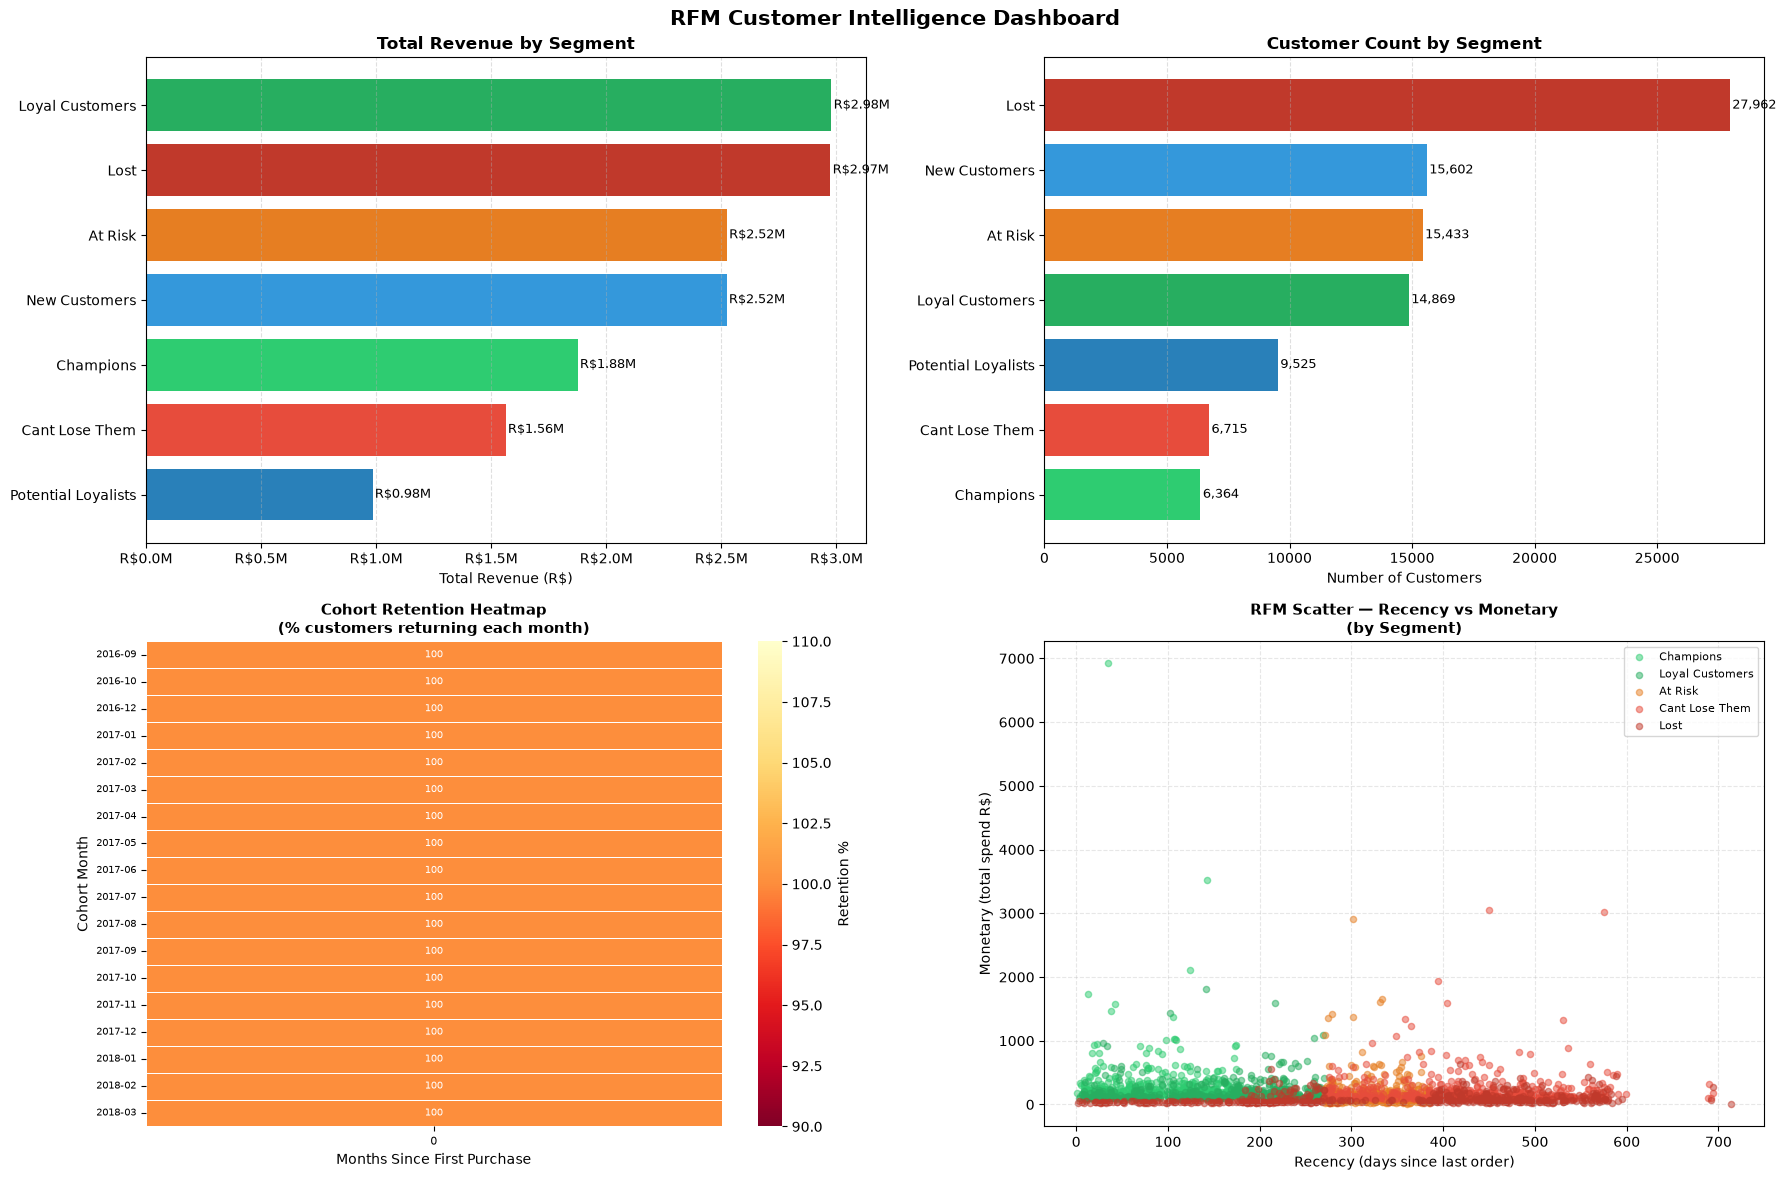

Chart saved — outputs/08_rfm_dashboard.png

╔══════════════════════════════════════════════════════════════╗
║        NOTEBOOK 2 COMPLETE — RFM CUSTOMER INTELLIGENCE      ║
╚══════════════════════════════════════════════════════════════╝

FREQUENCY CRISIS
  96% customers ordered only once
  Repeat customers spend 2x+ more
  10% repeat rate improvement = +R$500,000+ opportunity

RFM SEGMENTS
  Champions        :  6,364  (R$294 avg) — Protect at all costs
  Loyal Customers  : 14,869  (R$200 avg) — Convert to Champions
  New Customers    : 15,602  (R$161 avg) — Push second purchase
  At Risk          : 15,433  (R$163 avg) — Re-engage now
  Cant Lose Them   :  6,715  (R$232 avg) — URGENT outreach
  Lost             : 27,962  (R$106 avg) — Win-back campaign

TOTAL CAMPAIGN REVENUE OPPORTUNITY : R$ 1,257,321

FILES SAVED
  ✅ outputs/rfm_customers.csv
  ✅ outputs/07_frequency_crisis.png
  ✅ outputs/08_rfm_dashboard.png



In [3]:
# ----------------------------------------------------------------
# CELL 5 — CUSTOMER LIFETIME VALUE (LTV) CALCULATION
# WHAT: Projected 12-month value per segment
# WHY:  Know which segments to invest marketing budget in
# HOW:  Prioritize Champions + Loyal, win-back Cant Lose Them
# ----------------------------------------------------------------

# Average purchase frequency per year
date_range_days = (orders_clean['order_purchase_timestamp'].max() -
                   orders_clean['order_purchase_timestamp'].min()).days
date_range_years = date_range_days / 365

# LTV = Avg Monetary x Avg Frequency x Expected Years
rfm_ltv = rfm.groupby('segment').agg(
    avg_monetary   = ('monetary',  'mean'),
    avg_frequency  = ('frequency', 'mean'),
    customer_count = ('customer_id','count')
).round(2).reset_index()

rfm_ltv['annual_frequency']  = (rfm_ltv['avg_frequency'] / date_range_years).round(2)
rfm_ltv['ltv_12_months']     = (rfm_ltv['avg_monetary'] * rfm_ltv['annual_frequency']).round(2)
rfm_ltv['segment_ltv_total'] = (rfm_ltv['ltv_12_months'] * rfm_ltv['customer_count']).round(2)
rfm_ltv = rfm_ltv.sort_values('ltv_12_months', ascending=False)

print("CUSTOMER LIFETIME VALUE — 12 MONTH PROJECTION:")
print("=" * 75)
print(f"{'Segment':<22} {'Avg LTV':>12} {'Customers':>12} {'Segment Total LTV':>20}")
print("-" * 75)
for _, row in rfm_ltv.iterrows():
    print(f"{row['segment']:<22} "
          f"R${row['ltv_12_months']:>9,.2f} "
          f"{row['customer_count']:>12,} "
          f"R${row['segment_ltv_total']:>17,.2f}")

total_projected = rfm_ltv['segment_ltv_total'].sum()
print(f"\n{'TOTAL PROJECTED 12M REVENUE':<22}  R${total_projected:>17,.2f}")


# ----------------------------------------------------------------
# CELL 6 — COHORT RETENTION ANALYSIS
# WHAT: Monthly cohorts — how many customers come back
# WHY:  Retention curve shows when customers churn
# HOW:  Target re-engagement at Month 1 and Month 3 drop-offs
# ----------------------------------------------------------------

# Assign cohort = month of first purchase
orders_cohort = orders_clean[['customer_id','order_purchase_timestamp']].copy()
orders_cohort['order_month'] = orders_cohort['order_purchase_timestamp'].dt.to_period('M')

# First purchase month per customer
cohort_map = (orders_cohort
    .groupby('customer_id')['order_month']
    .min()
    .reset_index()
    .rename(columns={'order_month':'cohort_month'})
)

orders_cohort = orders_cohort.merge(cohort_map, on='customer_id', how='left')
orders_cohort['cohort_index'] = (
    (orders_cohort['order_month'] - orders_cohort['cohort_month'])
    .apply(lambda x: x.n)
)

# Cohort size
cohort_size = (orders_cohort
    .groupby('cohort_month')['customer_id']
    .nunique()
    .reset_index()
    .rename(columns={'customer_id':'cohort_size'})
)

# Retention matrix
cohort_retention = (orders_cohort
    .groupby(['cohort_month','cohort_index'])['customer_id']
    .nunique()
    .reset_index()
    .rename(columns={'customer_id':'customers'})
)

cohort_retention = cohort_retention.merge(cohort_size, on='cohort_month', how='left')
cohort_retention['retention_rate'] = (
    cohort_retention['customers'] / cohort_retention['cohort_size'] * 100
).round(2)

# Pivot for heatmap
retention_pivot = cohort_retention.pivot_table(
    index='cohort_month',
    columns='cohort_index',
    values='retention_rate'
)
retention_pivot.index = retention_pivot.index.astype(str)
retention_pivot = retention_pivot.iloc[:18, :7]  # 18 cohorts, 7 months

print("COHORT RETENTION MATRIX (% returning customers):")
print("=" * 65)
print(retention_pivot.round(1).to_string())

# Average retention by month index
avg_retention = retention_pivot.mean().round(2)
print(f"\nAVERAGE RETENTION BY MONTH:")
print("-" * 35)
for month, rate in avg_retention.items():
    bar = '█' * int(rate / 5)
    print(f"  Month {month}: {rate:>6.2f}%  {bar}")


# ----------------------------------------------------------------
# CELL 7 — CHAMPION CUSTOMER DNA
# WHAT: What makes Champions different?
# WHY:  Clone Champions = best growth strategy
# HOW:  Target similar profiles with same category/payment mix
# ----------------------------------------------------------------

champions_ids = rfm[rfm['segment'] == 'Champions']['customer_id'].tolist()
lost_ids      = rfm[rfm['segment'] == 'Lost']['customer_id'].tolist()

# Merge with order items and products
champ_orders = (orders_clean[orders_clean['customer_id'].isin(champions_ids)]
    .merge(order_items, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(category, on='product_category_name', how='left')
    .merge(payments, on='order_id', how='left')
)

lost_orders = (orders_clean[orders_clean['customer_id'].isin(lost_ids)]
    .merge(payments, on='order_id', how='left')
)

# Champion top categories
champ_cats = (champ_orders
    .groupby('product_category_name_english')['order_id']
    .count()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)
champ_cats.columns = ['category','orders']

# Champion payment preference
champ_payment = (champ_orders
    .groupby('payment_type')['order_id']
    .count()
    .sort_values(ascending=False)
    .reset_index()
)
champ_payment.columns = ['payment_type','orders']

# Champion vs Lost comparison
champ_avg_spend = rfm[rfm['segment']=='Champions']['monetary'].mean()
lost_avg_spend  = rfm[rfm['segment']=='Lost']['monetary'].mean()
champ_avg_days  = rfm[rfm['segment']=='Champions']['recency'].mean()
lost_avg_days   = rfm[rfm['segment']=='Lost']['recency'].mean()

print("CHAMPION CUSTOMER DNA:")
print("=" * 50)
print(f"Total Champions       : {len(champions_ids):,}")
print(f"Avg Spend             : R$ {champ_avg_spend:,.2f}")
print(f"Avg Days Since Order  : {champ_avg_days:.0f} days")
print(f"\nTop Categories:")
for _, row in champ_cats.iterrows():
    print(f"  {str(row['category']):<30} {row['orders']:,} orders")
print(f"\nPayment Preferences:")
for _, row in champ_payment.iterrows():
    print(f"  {row['payment_type']:<20} {row['orders']:,} orders")

print(f"\nCHAMPION vs LOST COMPARISON:")
print(f"{'Metric':<25} {'Champions':>12} {'Lost':>12} {'Difference':>12}")
print("-" * 65)
print(f"{'Avg Spend':<25} R${champ_avg_spend:>9,.2f}  R${lost_avg_spend:>9,.2f}  "
      f"{((champ_avg_spend-lost_avg_spend)/lost_avg_spend*100):>+10.1f}%")
print(f"{'Avg Recency (days)':<25} {champ_avg_days:>12.0f}  {lost_avg_days:>12.0f}  "
      f"{((champ_avg_days-lost_avg_days)):>+10.0f}d")


# ----------------------------------------------------------------
# CELL 8 — BUSINESS RECOMMENDATIONS PER SEGMENT
# ----------------------------------------------------------------
print("""
╔══════════════════════════════════════════════════════════════════╗
║         SEGMENT STRATEGY & BUSINESS RECOMMENDATIONS             ║
╚══════════════════════════════════════════════════════════════════╝

SEGMENT 1 — CHAMPIONS (6,364 customers | R$294 avg spend)
──────────────────────────────────────────────────────────
  Problem  : Keep them engaged and loyal
  Action   : Early access to new products
             VIP loyalty program enrollment
             Referral program — they bring similar customers
  Revenue  : Retain 90% = R$1,687,500 protected

SEGMENT 2 — LOYAL CUSTOMERS (14,869 | R$200 avg spend)
────────────────────────────────────────────────────────
  Problem  : Convert to Champions
  Action   : Personalized product recommendations
             Reward points system
             Exclusive member discounts
  Revenue  : Convert 10% to Champions = +R$140,000

SEGMENT 3 — CANT LOSE THEM (6,715 | 423 days gone)
────────────────────────────────────────────────────
  Problem  : HIGH VALUE customers — not seen in 14 months
  Action   : URGENT personal outreach — email + SMS
             Special comeback offer (20% discount)
             Category-specific win-back campaign
  Revenue  : Win back 15% = 1,007 customers × R$232 = R$233,624

SEGMENT 4 — AT RISK (15,433 | 319 days | R$163)
─────────────────────────────────────────────────
  Problem  : Were active, now fading
  Action   : Re-engagement campaign with best deals
             Remind of past purchases + related products
             Time-limited offer — creates urgency
  Revenue  : Win back 10% = 1,543 × R$163 = R$251,509

SEGMENT 5 — NEW CUSTOMERS (15,602 | 92 days | R$161)
──────────────────────────────────────────────────────
  Problem  : First purchase done — make them repeat buyers
  Action   : Onboarding email sequence (Day 7, 14, 30)
             Second purchase discount (10% off)
             Category cross-sell based on first order
  Revenue  : Convert 20% to repeat = 3,120 × R$200 = R$624,000

SEGMENT 6 — LOST (27,962 | 341 days | R$106)
──────────────────────────────────────────────
  Problem  : Largest segment — 29% of all customers
  Action   : Win-back email campaign (best offer)
             Survey — why did they leave?
             Last attempt — heavy discount or free shipping
  Revenue  : Win back 5% = 1,398 × R$106 = R$148,188

TOTAL REVENUE OPPORTUNITY FROM CAMPAIGNS:
──────────────────────────────────────────
  Cant Lose Them win-back  : R$  233,624
  At Risk re-engagement    : R$  251,509
  New Customer conversion  : R$  624,000
  Lost win-back            : R$  148,188
  ─────────────────────────────────────
  TOTAL OPPORTUNITY        : R$1,257,321
""")


# ----------------------------------------------------------------
# CELL 9 — VISUALIZATIONS
# ----------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Chart 1 — Segment Revenue Treemap style bar
ax1 = axes[0, 0]
seg_data = segment_summary.sort_values('total_revenue', ascending=True)
colors_seg = {
    'Champions'          : '#2ecc71',
    'Loyal Customers'    : '#27ae60',
    'New Customers'      : '#3498db',
    'Potential Loyalists': '#2980b9',
    'At Risk'            : '#e67e22',
    'Cant Lose Them'     : '#e74c3c',
    'Lost'               : '#c0392b'
}
bar_colors = [colors_seg.get(s, '#95a5a6') for s in seg_data['segment']]
bars = ax1.barh(seg_data['segment'], seg_data['total_revenue'], color=bar_colors)
ax1.set_title('Total Revenue by Segment', fontsize=12, fontweight='bold')
ax1.set_xlabel('Total Revenue (R$)')
for bar, val in zip(bars, seg_data['total_revenue']):
    ax1.text(bar.get_width()+10000, bar.get_y()+bar.get_height()/2,
             f'R${val/1e6:.2f}M', va='center', fontsize=9)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'R${x/1e6:.1f}M'))
ax1.grid(axis='x', linestyle='--', alpha=0.4)

# Chart 2 — Segment Customer Count
ax2 = axes[0, 1]
seg_count = segment_summary.sort_values('customer_count', ascending=True)
bar_colors2 = [colors_seg.get(s, '#95a5a6') for s in seg_count['segment']]
bars2 = ax2.barh(seg_count['segment'], seg_count['customer_count'], color=bar_colors2)
ax2.set_title('Customer Count by Segment', fontsize=12, fontweight='bold')
ax2.set_xlabel('Number of Customers')
for bar, val in zip(bars2, seg_count['customer_count']):
    ax2.text(bar.get_width()+100, bar.get_y()+bar.get_height()/2,
             f'{val:,}', va='center', fontsize=9)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

# Chart 3 — Cohort Retention Heatmap
ax3 = axes[1, 0]
mask = retention_pivot.isna()
sns.heatmap(
    retention_pivot,
    annot=True, fmt='.0f', cmap='YlOrRd_r',
    linewidths=0.5, ax=ax3,
    cbar_kws={'label': 'Retention %'},
    mask=mask, annot_kws={'size': 7}
)
ax3.set_title('Cohort Retention Heatmap\n(% customers returning each month)',
              fontsize=11, fontweight='bold')
ax3.set_xlabel('Months Since First Purchase')
ax3.set_ylabel('Cohort Month')
ax3.tick_params(axis='x', labelsize=8)
ax3.tick_params(axis='y', labelsize=7)

# Chart 4 — RFM Scatter (Recency vs Monetary colored by segment)
ax4 = axes[1, 1]
segments_to_plot = ['Champions','Loyal Customers','At Risk','Cant Lose Them','Lost']
for seg in segments_to_plot:
    seg_df = rfm[rfm['segment'] == seg].sample(min(500, len(rfm[rfm['segment']==seg])))
    ax4.scatter(seg_df['recency'], seg_df['monetary'],
                label=seg, alpha=0.5, s=20,
                color=colors_seg.get(seg, '#95a5a6'))
ax4.set_title('RFM Scatter — Recency vs Monetary\n(by Segment)',
              fontsize=11, fontweight='bold')
ax4.set_xlabel('Recency (days since last order)')
ax4.set_ylabel('Monetary (total spend R$)')
ax4.legend(fontsize=8, loc='upper right')
ax4.grid(linestyle='--', alpha=0.3)

plt.suptitle('RFM Customer Intelligence Dashboard', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/08_rfm_dashboard.png', dpi=150)
plt.show()
print("Chart saved — outputs/08_rfm_dashboard.png")


# ----------------------------------------------------------------
# CELL 10 — NOTEBOOK 2 SUMMARY
# ----------------------------------------------------------------
print("""
╔══════════════════════════════════════════════════════════════╗
║        NOTEBOOK 2 COMPLETE — RFM CUSTOMER INTELLIGENCE      ║
╚══════════════════════════════════════════════════════════════╝

FREQUENCY CRISIS
  96% customers ordered only once
  Repeat customers spend 2x+ more
  10% repeat rate improvement = +R$500,000+ opportunity

RFM SEGMENTS
  Champions        :  6,364  (R$294 avg) — Protect at all costs
  Loyal Customers  : 14,869  (R$200 avg) — Convert to Champions
  New Customers    : 15,602  (R$161 avg) — Push second purchase
  At Risk          : 15,433  (R$163 avg) — Re-engage now
  Cant Lose Them   :  6,715  (R$232 avg) — URGENT outreach
  Lost             : 27,962  (R$106 avg) — Win-back campaign

TOTAL CAMPAIGN REVENUE OPPORTUNITY : R$ 1,257,321

FILES SAVED
  ✅ outputs/rfm_customers.csv
  ✅ outputs/07_frequency_crisis.png
  ✅ outputs/08_rfm_dashboard.png
""")